In [183]:
import numpy as np
import matplotlib.pyplot as plt
import graphviz
from graphviz import Digraph
import random

In [183]:
import numpy as np
import matplotlib.pyplot as plt
import graphviz
from graphviz import Digraph
import random

In [218]:
#Engine
class Value:
    def __init__(self,data,_child=(),_op='',label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda:None
        self._prev = set(_child)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f'Value(data={self.data})'
        
    def __add__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        result = Value(self.data + other.data,(self,other),'+')
        def _backward():
            self.grad += 1.0 * result.grad
            other.grad += 1.0 * result.grad
        result._backward = _backward
        return result
        
    def __mul__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        result = Value(self.data * other.data,(self,other),'*')
        def _backward():
            self.grad += other.data * result.grad
            other.grad += self.data * result.grad
        result._backward = _backward
        return result
    def __pow__(self,other):
        assert isinstance(other,(int,float))
        result = Value(self.data**other,(self,),f'**{other}')
        def _backward():
            self.grad += (other * (self.data**(other-1))) * result.grad
        result._backward = _backward
        return result
            
    def __rmul__(self,other):
        return self * other

    def __truediv__(self,other):
        other = other if isinstance(other,Value) else  Value(other)
        return self * other**-1
    
    def __neg__(self):
        return self * -1
        
    def __sub__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        return self + (-other)
        
    def exp(self):
        x = self.data
        result = Value(np.exp(x),(self),'exp')
        def _backward():
            self.grad += result.data * result.grad
        result._backward = _backward
        return result
    
    def tanh(self):
        x = self.data
        t = (np.exp(2*x)-1)/(np.exp(2*x)+1)
        result = Value(t,(self,),'tanh')
        def _backward():
            self.grad += (1 - t ** 2 ) * result.grad
        result._backward = _backward
        return result
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
                


In [219]:
#graph
def trace(root):
    nodes,edges = set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes,edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid,label = '{%s|data %.4f|grad %.4f}' % ( n.label ,n.data,n.grad),shape='record')
        if n._op:
            dot.node(name =uid + n._op,label=n._op)
            dot.edge(uid + n._op,uid)
    for n1,n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot
            
    

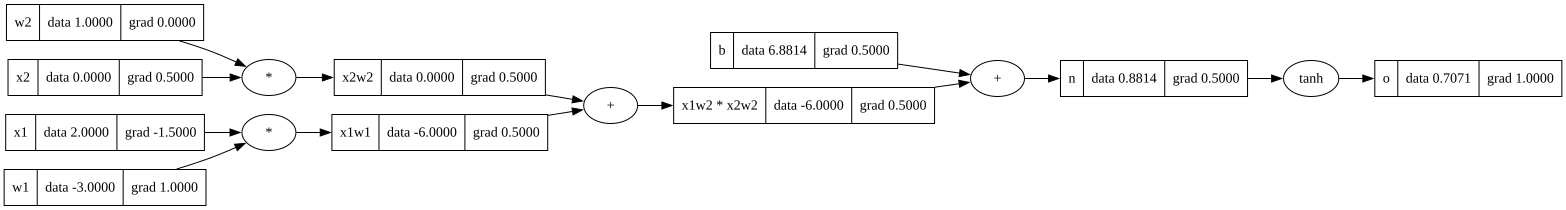

In [220]:
##input x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
#weight w1,w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
#bais
b = Value(6.8813735870195432,label='b')
#x1w1 *x2w2+ b
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1w2 * x2w2'

n = x1w1x2w2 +b; n.label='n'
o = n.tanh();o.label='o'
o.backward()
draw_dot(o)

In [221]:
class Neuron:
    def __init__(self,nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] 
        self.b = Value(random.uniform(-1,1))
    def __call__(self, x):
        x = [xi if isinstance(xi, Value) else Value(xi) for xi in x]  
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return act.tanh()
    
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def __call__(self,x):
        result = [n(x) for n in self.neurons]
        return result[0] if len(result) == 1 else result
    def parameters(self):
        return [ p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self,nin,nouts):
        sz = [nin] + nouts
        self.layer = [Layer(sz[i],sz[i+1]) for i in range (len((nouts)))]
    def __call__(self,x):
        for layer in self.layer:
            x = layer(x)
        return x
    def parameters(self):
        return [ p for layer in self.layer for p in layer.parameters()]
            
        
        
        

    
    

In [222]:
x = [ 2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data=-0.39707985849363314)

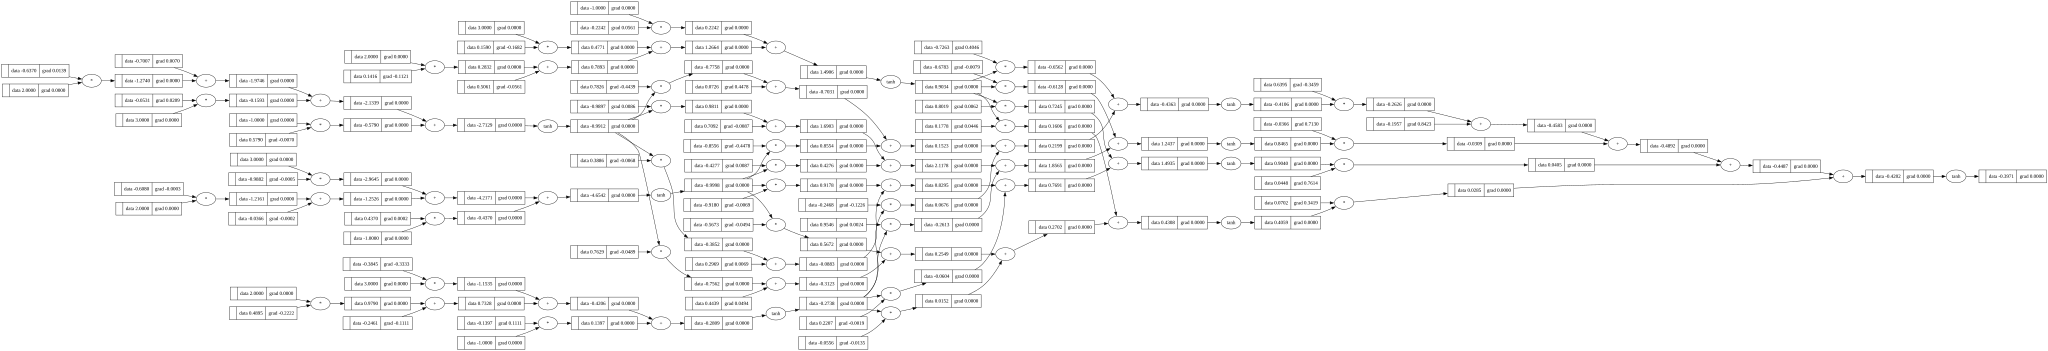

In [223]:
n(x).backward()
draw_dot(n(x))

In [224]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [1.0,1.0,1.0],
    [1.0,1.0,-1.0]
]

ys = [1.0,-1.0,-1.0]# desired target
ypred = [n(x) for x in xs]
ypred


[Value(data=-0.39707985849363314),
 Value(data=-0.5589280554415388),
 Value(data=-0.18704398263712813),
 Value(data=-0.39086652142311323)]

In [225]:
n.layer[0].neurons[0].w[0].data


-0.6369961555228305

In [226]:
lr = 0.0001
for k in range(10):
    ypred = [n(x) for x in xs]
    loss=sum(((yout - ygt )**2 for ygt ,yout in zip(ys,ypred)),Value(0.0))

    for p in n.parameters():
        p.grad = 0.0

    loss.backward()

    for p in n.parameters():
        p.data += -lr * p.grad
        
    print(k,loss.data)

0 2.8072740774516745
1 2.8068323998319755
2 2.806390800072772
3 2.805949277839559
4 2.805507832798389
5 2.80506646461587
6 2.804625172959166
7 2.8041839574959946
8 2.8037428178946193
9 2.8033017538238565


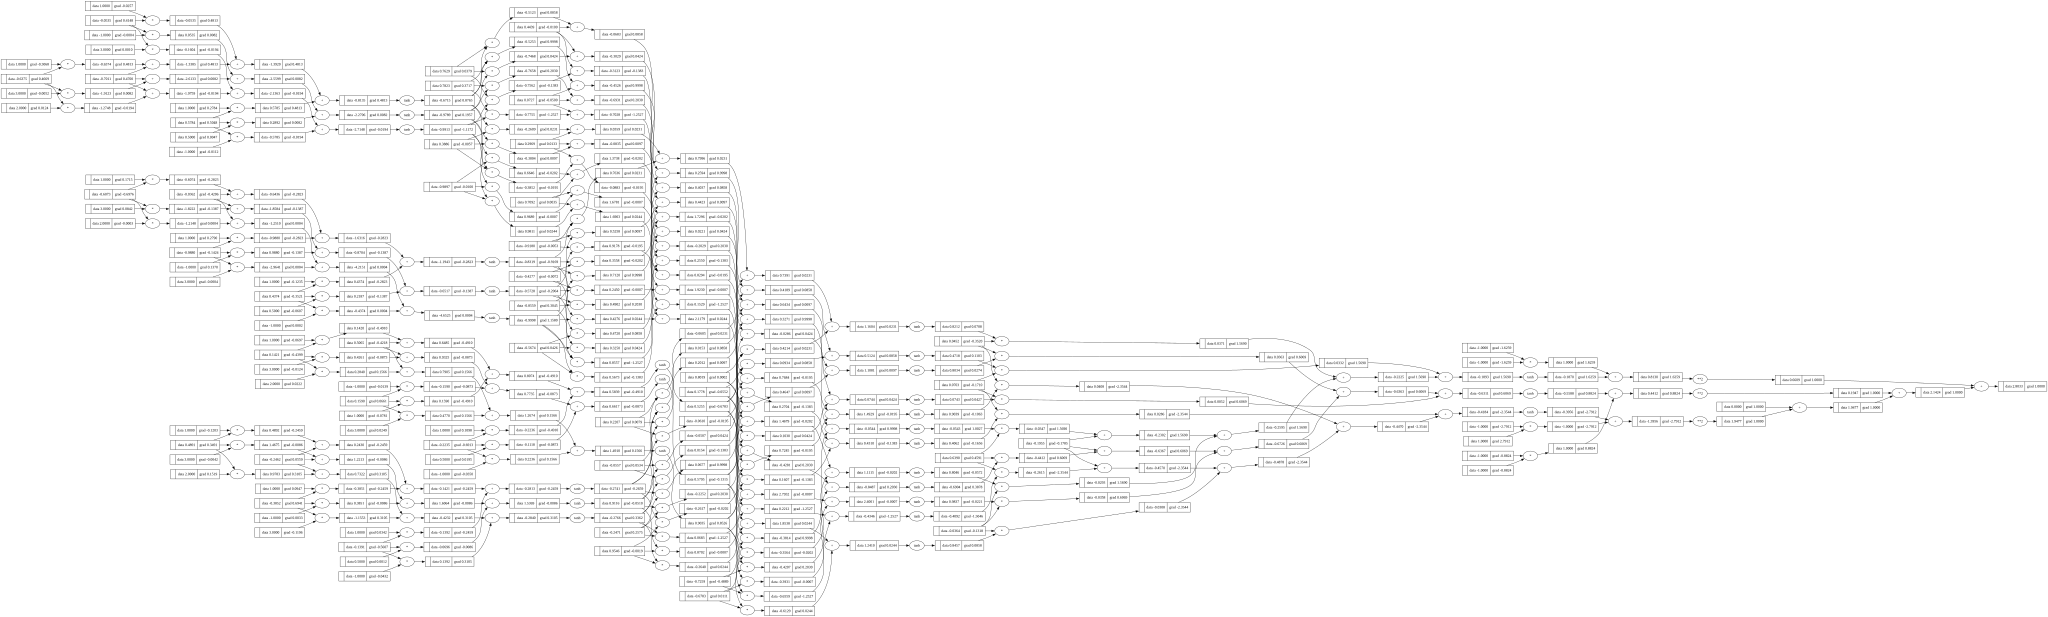

In [227]:

draw_dot(loss)